# Análisis comparativo de los algoritmos genéticos

Este notebook compara `genetic_schedule.py` (original) y `better_genetic_schedule.py` (mejorado) en **tiempo de ejecución**, **generaciones** y **calidad del horario**. Presenta tablas, estadísticas y gráficas con Matplotlib.

Puedes analizar el archivo `comparacion_algoritmos.csv` existente o volver a ejecutar ambos algoritmos con varias semillas. El modo de ejecución está desactivado por defecto para que el notebook pueda analizar los resultados guardados sin esperar a que corran los algoritmos.

> Ejecuta las celdas en orden. Si faltan dependencias, instálalas en el entorno del kernel con `%pip install pandas matplotlib`.

## Metodología y precauciones

- Cada par de ejecuciones utiliza la misma semilla y los mismos parámetros de población y generaciones máximas.
- `fitness_propio` y sus violaciones se calculan con las reglas de cada implementación. **No se deben comparar directamente**: el algoritmo mejorado usa reglas y restricciones adicionales.
- `fitness_comun`, `duras_comun` y `blandas_comun` evalúan ambos horarios con el evaluador del algoritmo original. Esto facilita la comparación, pero no mide las restricciones adicionales del mejorado.
- El tiempo incluye la ejecución del algoritmo y su reparación final; excluye la carga inicial de los módulos. El tiempo puede variar por hardware, carga del sistema y calentamiento de Python.
- Unas pocas ejecuciones son indicativas, no una prueba estadística concluyente. Para una conclusión más robusta, activa nuevas ejecuciones y aumenta el número de semillas.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE_DIR = Path.cwd()
CSV_PATH = BASE_DIR / "comparacion_algoritmos.csv"
ALGORITMOS = ["Original", "Mejorado"]
COLORES = {"Original": "#4C78A8", "Mejorado": "#F58518"}

plt.style.use("seaborn-v0_8-whitegrid")
print(f"Carpeta de análisis: {BASE_DIR}")
print(f"Archivo de resultados: {CSV_PATH}")

Carpeta de análisis: c:\Users\Usuario\Documents\GitHub\SchoolSchedule-GeneticAlgorithm
Archivo de resultados: c:\Users\Usuario\Documents\GitHub\SchoolSchedule-GeneticAlgorithm\comparacion_algoritmos.csv


## 1. Configuración de ejecuciones (opcional)

Deja `RUN_EXPERIMENTS = False` para conservar y analizar el CSV existente. Si lo cambias a `True`, se ejecutarán ambos algoritmos y se **sobrescribirá** `comparacion_algoritmos.csv` con los nuevos resultados. Las semillas de cada par serán iguales.

In [ ]:
RUN_EXPERIMENTS = False
NUM_RUNS = 10
POPULATION_SIZE = 120
MAX_GENERATIONS = 400
FIRST_SEED = 7

if RUN_EXPERIMENTS:
    import argparse
    import comparar_algoritmos

    config = argparse.Namespace(
        runs=NUM_RUNS,
        population=POPULATION_SIZE,
        generations=MAX_GENERATIONS,
        seed=FIRST_SEED,
        output=CSV_PATH,
    )
    comparar_algoritmos.ejecutar_comparacion(config)
else:
    print("Se analizarán los resultados guardados; no se ejecutarán los algoritmos.")

KeyboardInterrupt: 

In [ ]:
COLUMNAS_REQUERIDAS = {
    "algoritmo", "ejecucion", "semilla", "tiempo_segundos", "generaciones",
    "fitness_propio", "duras_propio", "blandas_propio", "fitness_comun",
    "duras_comun", "blandas_comun",
}

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"No existe {CSV_PATH}. Ejecuta comparar_algoritmos.py o activa RUN_EXPERIMENTS."
    )

df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")
faltantes = COLUMNAS_REQUERIDAS.difference(df.columns)
if faltantes:
    raise ValueError(f"El CSV no contiene las columnas requeridas: {sorted(faltantes)}")
if df.empty:
    raise ValueError("El CSV no contiene resultados para analizar.")

columnas_numericas = sorted(COLUMNAS_REQUERIDAS - {"algoritmo"})
df[columnas_numericas] = df[columnas_numericas].apply(pd.to_numeric, errors="raise")
algoritmos_encontrados = set(df["algoritmo"].unique())
if algoritmos_encontrados != set(ALGORITMOS):
    raise ValueError(f"Se esperaban {ALGORITMOS}; se encontraron {sorted(algoritmos_encontrados)}")
if df.duplicated(["algoritmo", "ejecucion"]).any():
    raise ValueError("Hay ejecuciones duplicadas para un mismo algoritmo.")

pares = df.pivot(index="ejecucion", columns="algoritmo", values="semilla")
if pares[ALGORITMOS].isna().any().any() or not (pares["Original"] == pares["Mejorado"]).all():
    raise ValueError("Las ejecuciones no están emparejadas por número y semilla.")

df = df.sort_values(["ejecucion", "algoritmo"]).reset_index(drop=True)
print(f"Resultados cargados: {len(df)} filas, {df['ejecucion'].nunique()} pares de ejecuciones")
display(df)

Resultados cargados: 20 filas, 10 pares de ejecuciones


,algoritmo,ejecucion,semilla,tiempo_segundos,generaciones,fitness_propio,duras_propio,blandas_propio,fitness_comun,duras_comun,blandas_comun
0,Mejorado,1,7,0.124982,1,0.166667,0,5,0.166667,0,5
1,Original,1,7,13.994822,400,0.166667,0,5,0.166667,0,5
2,Mejorado,2,8,0.125450,1,0.166667,0,5,0.166667,0,5
3,Original,2,8,12.768057,400,0.166667,0,5,0.166667,0,5
4,Mejorado,3,9,0.143768,1,0.166667,0,5,0.166667,0,5
5,Original,3,9,12.448413,400,0.166667,0,5,0.166667,0,5
6,Mejorado,4,10,0.148653,1,0.166667,0,5,0.166667,0,5
7,Original,4,10,13.309487,400,0.166667,0,5,0.166667,0,5
8,Mejorado,5,11,0.250655,1,0.166667,0,5,0.166667,0,5
9,Original,5,11,13.273705,400,0.166667,0,5,0.166667,0,5


## 2. Resumen estadístico

Se reportan media, mediana, desviación estándar, mínimo y máximo. Para conjuntos de una sola ejecución la desviación estándar no está definida.

In [ ]:
metricas = [
    "tiempo_segundos", "generaciones", "fitness_propio", "duras_propio", "blandas_propio",
    "fitness_comun", "duras_comun", "blandas_comun",
]
estadisticas = df.groupby("algoritmo")[metricas].agg(["mean", "median", "std", "min", "max"])
display(estadisticas.round(4))

resumen = df.groupby("algoritmo")[metricas].mean().reindex(ALGORITMOS)
print("Promedios por algoritmo:")
display(resumen.round(4))

NameError: name 'df' is not defined

## 3. Rendimiento: tiempo y generaciones

La primera gráfica permite ver la variabilidad entre pares. El eje logarítmico de tiempos ayuda cuando los algoritmos difieren mucho en velocidad. La segunda compara medias y desviaciones estándar.

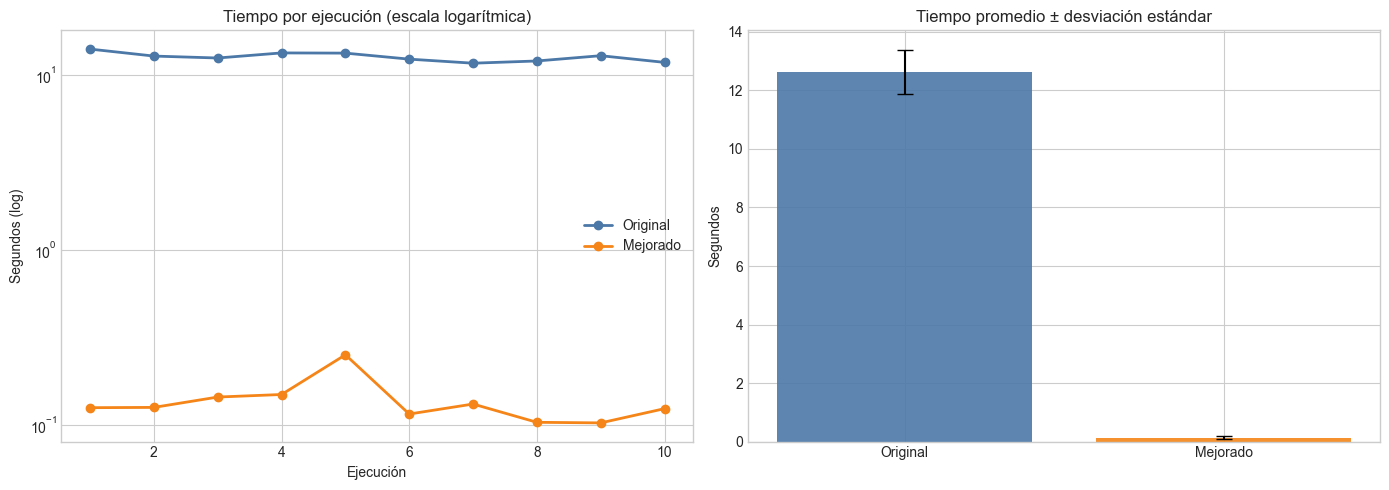

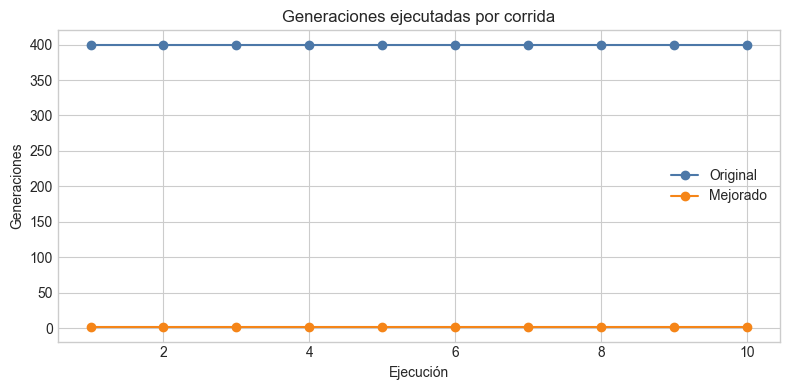

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for algoritmo in ALGORITMOS:
    parte = df[df["algoritmo"] == algoritmo]
    axes[0].plot(
        parte["ejecucion"], parte["tiempo_segundos"], marker="o", linewidth=2,
        label=algoritmo, color=COLORES[algoritmo],
    )
axes[0].set_yscale("log")
axes[0].set_title("Tiempo por ejecución (escala logarítmica)")
axes[0].set_xlabel("Ejecución")
axes[0].set_ylabel("Segundos (log)")
axes[0].legend()

medias_tiempo = df.groupby("algoritmo")["tiempo_segundos"].mean().reindex(ALGORITMOS)
desv_tiempo = df.groupby("algoritmo")["tiempo_segundos"].std().reindex(ALGORITMOS).fillna(0)
axes[1].bar(
    ALGORITMOS, medias_tiempo, yerr=desv_tiempo, capsize=6,
    color=[COLORES[a] for a in ALGORITMOS], alpha=0.9,
)
axes[1].set_title("Tiempo promedio ± desviación estándar")
axes[1].set_ylabel("Segundos")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for algoritmo in ALGORITMOS:
    parte = df[df["algoritmo"] == algoritmo]
    ax.plot(parte["ejecucion"], parte["generaciones"], marker="o", label=algoritmo, color=COLORES[algoritmo])
ax.set_title("Generaciones ejecutadas por corrida")
ax.set_xlabel("Ejecución")
ax.set_ylabel("Generaciones")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Calidad de los horarios

Las violaciones y el fitness **comunes** usan el evaluador original para ambos resultados. El fitness **propio** se muestra por separado para dar contexto sobre la puntuación que reporta cada implementación; no es una comparación equivalente.

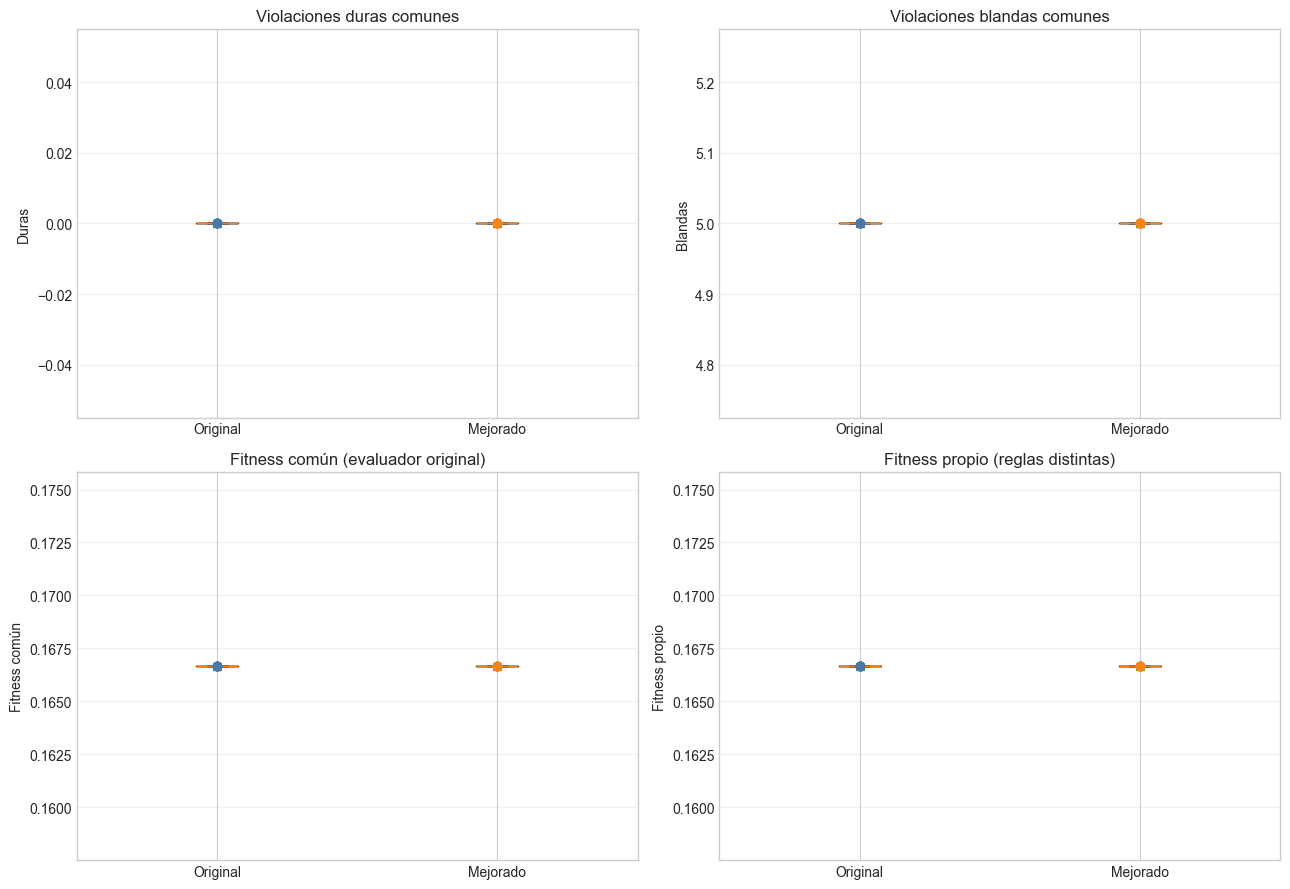

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
metricas_calidad = [
    ("duras_comun", "Violaciones duras comunes", "Duras"),
    ("blandas_comun", "Violaciones blandas comunes", "Blandas"),
    ("fitness_comun", "Fitness común (evaluador original)", "Fitness común"),
    ("fitness_propio", "Fitness propio (reglas distintas)", "Fitness propio"),
]

for ax, (metrica, titulo, ylabel) in zip(axes.flat, metricas_calidad):
    valores = [df.loc[df["algoritmo"] == algoritmo, metrica].to_numpy() for algoritmo in ALGORITMOS]
    ax.boxplot(valores, showmeans=True)
    ax.set_xticks([1, 2], ALGORITMOS)
    for x, algoritmo in enumerate(ALGORITMOS, start=1):
        parte = df[df["algoritmo"] == algoritmo]
        ax.scatter(
            [x] * len(parte), parte[metrica], color=COLORES[algoritmo], alpha=0.65, zorder=3,
        )
    ax.set_title(titulo)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## 5. Comparación pareada por semilla

Al comparar cada par se reduce el efecto de usar entradas aleatorias diferentes. La gráfica presenta el tiempo de cada algoritmo para la misma semilla.

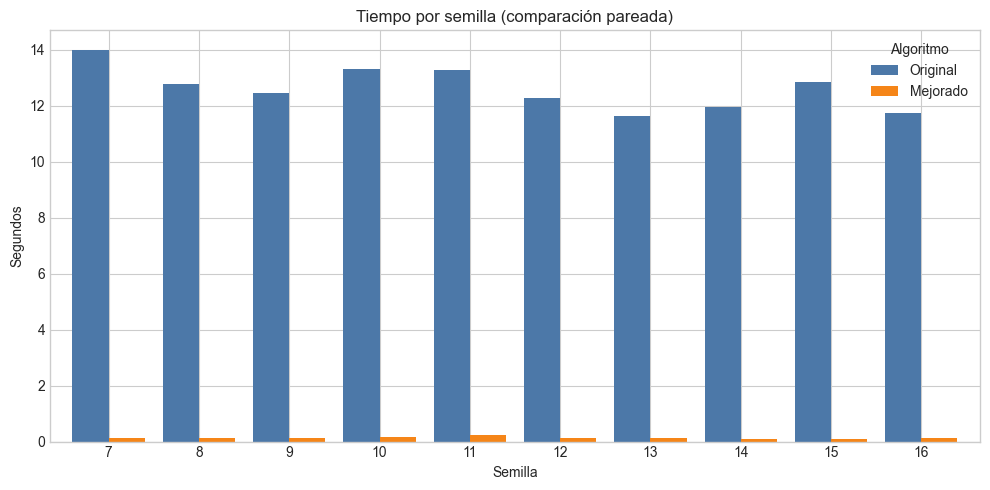

algoritmo,Mejorado,Original,razon_original_sobre_mejorado
semilla,,,
7,0.125,13.995,111.975
8,0.125,12.768,101.778
9,0.144,12.448,86.587
10,0.149,13.309,89.534
11,0.251,13.274,52.956
12,0.115,12.263,106.653
13,0.131,11.626,88.658
14,0.103,11.971,116.098
15,0.102,12.832,125.412


In [ ]:
tiempos_pareados = df.pivot(index="semilla", columns="algoritmo", values="tiempo_segundos").sort_index()
ax = tiempos_pareados[ALGORITMOS].plot(
    kind="bar", figsize=(10, 5), color=[COLORES[a] for a in ALGORITMOS], width=0.8,
)
ax.set_title("Tiempo por semilla (comparación pareada)")
ax.set_xlabel("Semilla")
ax.set_ylabel("Segundos")
ax.legend(title="Algoritmo")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(tiempos_pareados.assign(
    razon_original_sobre_mejorado=tiempos_pareados["Original"] / tiempos_pareados["Mejorado"]
).round(3))

## 6. Interpretación automática y conclusión

In [ ]:
promedio_original = df.loc[df["algoritmo"] == "Original", "tiempo_segundos"].mean()
promedio_mejorado = df.loc[df["algoritmo"] == "Mejorado", "tiempo_segundos"].mean()
if promedio_mejorado > 0:
    porcentaje_mas_rapido = (promedio_original - promedio_mejorado) / promedio_original * 100
    razon_velocidad = promedio_original / promedio_mejorado
else:
    porcentaje_mas_rapido = float("nan")
    razon_velocidad = float("nan")

duras_cero = df.groupby("algoritmo")["duras_comun"].apply(lambda s: (s == 0).mean() * 100)
blandas_media = df.groupby("algoritmo")["blandas_comun"].mean()
fitness_comun_media = df.groupby("algoritmo")["fitness_comun"].mean()
n_runs = df["ejecucion"].nunique()

print(f"Ejecuciones pareadas analizadas: {n_runs}")
print(f"Tiempo promedio original: {promedio_original:.4f} s")
print(f"Tiempo promedio mejorado: {promedio_mejorado:.4f} s")
print(f"Cambio de tiempo del mejorado frente al original: {porcentaje_mas_rapido:.2f}%")
print(f"Relación de tiempos (original / mejorado): {razon_velocidad:.2f}x")

for algoritmo in ALGORITMOS:
    print(
        f"{algoritmo}: horarios sin violaciones duras comunes = {duras_cero[algoritmo]:.1f}% | "
        f"violaciones blandas comunes promedio = {blandas_media[algoritmo]:.2f} | "
        f"fitness común promedio = {fitness_comun_media[algoritmo]:.6f}"
    )

if n_runs < 10:
    print("\nPrecaución: la muestra es pequeña. Ejecuta al menos 10-30 pares para conclusiones más estables.")
print("\nInterpreta el tiempo junto con la calidad: un algoritmo más rápido no necesariamente produce mejores horarios.")
print("Las métricas comunes solo representan las restricciones del evaluador original y no todas las del algoritmo mejorado.")

Ejecuciones pareadas analizadas: 10
Tiempo promedio original: 12.6238 s
Tiempo promedio mejorado: 0.1368 s
Cambio de tiempo del mejorado frente al original: 98.92%
Relación de tiempos (original / mejorado): 92.25x
Original: horarios sin violaciones duras comunes = 100.0% | violaciones blandas comunes promedio = 5.00 | fitness común promedio = 0.166667
Mejorado: horarios sin violaciones duras comunes = 100.0% | violaciones blandas comunes promedio = 5.00 | fitness común promedio = 0.166667

Interpreta el tiempo junto con la calidad: un algoritmo más rápido no necesariamente produce mejores horarios.
Las métricas comunes solo representan las restricciones del evaluador original y no todas las del algoritmo mejorado.
